# monitor_distribution: h against the GFF (Theorem 1.3)

This notebook only **reads** results: it never starts a simulation. Runs are started with `python custom_runs.py` in the Anaconda Prompt. Keep the notebook in the project folder (next to `custom_runs.py` and the folder `custom_packages`).

**Part A** reads the test-function run (`drc_testfun_runs`): the law of h(f) against the law of π^(-1/2) GFF(f).  
**Part B** reads the main run (`drc_runs`): covariance, variance and pictures of h against the GFF.

**How to read part A**
- *status* and *time used*: progress, time left, and the time spent on each L and in total.
- *trend with L*: `ratio` is Var h(f) / Var GFF(f) (should tend to 1), skewness and excess kurtosis should tend to 0 as L grows.
  `dev = (ratio - 1) / standard error`: if it stays large while the error bars are small, the difference is a finite-L effect and more samples will not remove it.
- *running estimates*: if the curves are flat at the right end and the bands shrink like 1/sqrt(N), more samples only shrink the bands.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from custom_packages import drc_sim as d
from custom_packages import gff_compare as gc
from custom_packages import test_functions as tf
from custom_packages import test_function_plots as tfp
from custom_packages import presentation_figures as pf      # figures for the slides -> Graficos/

name = "main"                          # run name used by test_functions.run_all()
funcs = tf.default_test_functions()    # must be the same functions that the run used

# Part A. Test functions

## A1. The test functions

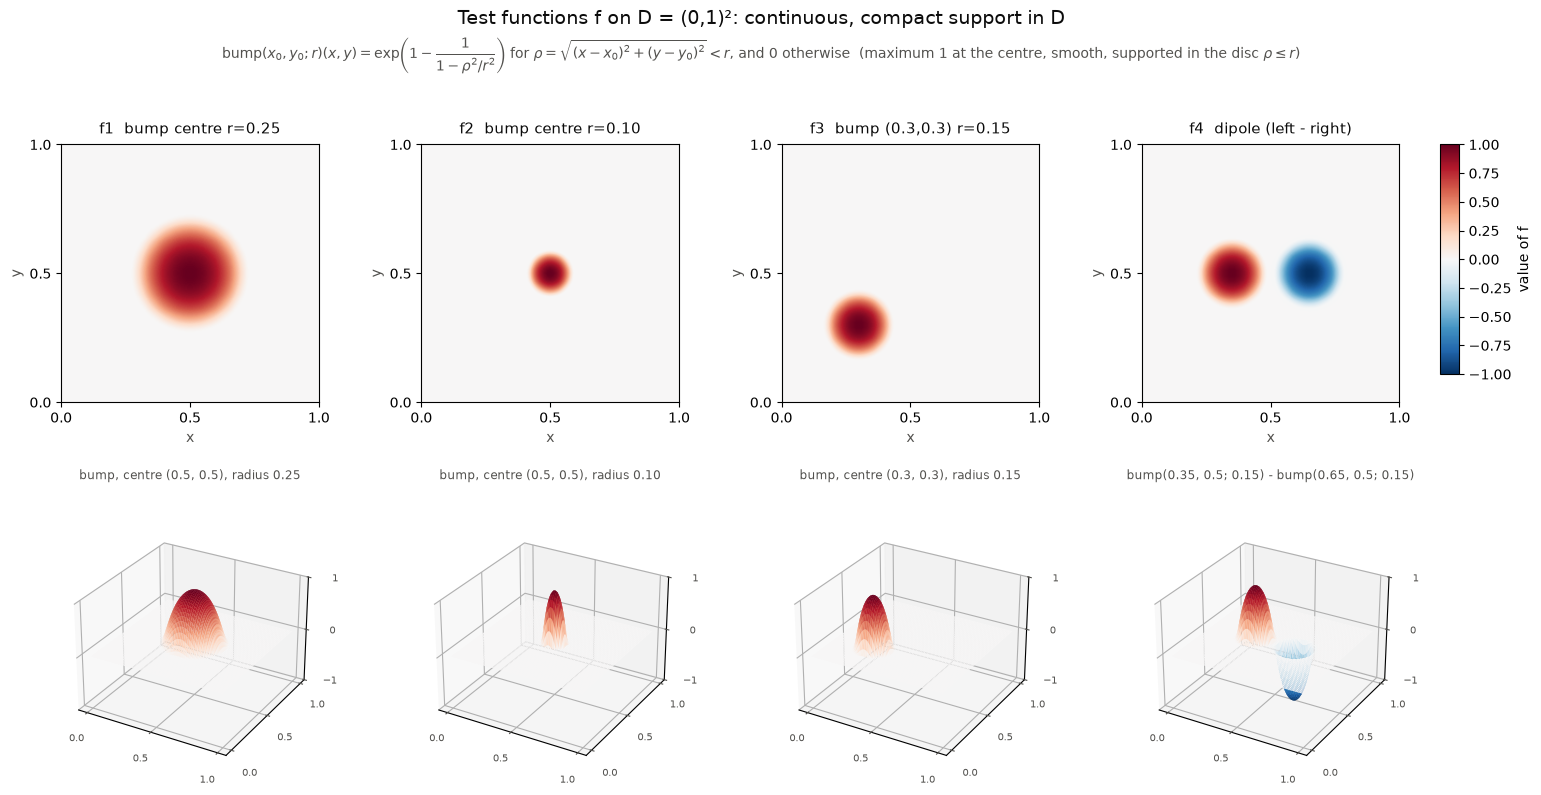

Test functions on D = (0,1)^2, all continuous with compact support inside D:
  bump(x0, y0; r)(x, y) = exp(1 - 1 / (1 - rho^2 / r^2)) if rho < r, 0 otherwise,  rho = |(x, y) - (x0, y0)|

  f1  bump centre r=0.25       bump, centre (0.5, 0.5), radius 0.25   [large, centred]
  f2  bump centre r=0.10       bump, centre (0.5, 0.5), radius 0.10   [small, centred (same centre as f1)]
  f3  bump (0.3,0.3) r=0.15    bump, centre (0.3, 0.3), radius 0.15   [off-centre]
  f4  dipole (left - right)    bump(0.35, 0.5; 0.15) - bump(0.65, 0.5; 0.15)   [antisymmetric: left minus right]


'Test functions on D = (0,1)^2, all continuous with compact support inside D:\n  bump(x0, y0; r)(x, y) = exp(1 - 1 / (1 - rho^2 / r^2)) if rho < r, 0 otherwise,  rho = |(x, y) - (x0, y0)|\n\n  f1  bump centre r=0.25       bump, centre (0.5, 0.5), radius 0.25   [large, centred]\n  f2  bump centre r=0.10       bump, centre (0.5, 0.5), radius 0.10   [small, centred (same centre as f1)]\n  f3  bump (0.3,0.3) r=0.15    bump, centre (0.3, 0.3), radius 0.15   [off-centre]\n  f4  dipole (left - right)    bump(0.35, 0.5; 0.15) - bump(0.65, 0.5; 0.15)   [antisymmetric: left minus right]'

In [2]:
tfp.plot_test_functions(save=pf.ruta("test_functions.png"))
plt.show()
tfp.describe()

## A2. Progress and time

In [3]:
tf.status(name)
print()
t = tf.time_report(name)

run 'main'  (18:13:32)   estimates assume 8 processes
    L  chains    samples done / target      %  in burn-in  core time  time left
  256  12/12        250,008 / 250,008    100.0           0     1.86 h        0 s
  512  12/12        250,008 / 250,008    100.0           0     8.70 h        0 s
 1024  12/12        250,008 / 250,008    100.0           0    40.23 h        0 s

estimated time left for everything started or expected: 0 s (a size that has not started yet is not counted unless it appears in CONFIG)

time used by run 'main'
    L    samples   core time   wall-clock   s / sample / core
  256    250,008      1.86 h     18.7 min              0.0268
  512    250,008      8.70 h     87.5 min              0.1253
 1024    250,008     40.23 h       6.72 h              0.5792
TOTAL    750,024     50.79 h       8.49 h
(core time includes burn-in; wall-clock counts only runs started with run_all; if the window was closed during a run, up to one minute of that session is missing)


## A3. Trend with L (all samples so far)


bump centre r=0.25
     L   samples      ratio h/GFF    dev       skewness   excess kurtosis   se(ratio) at 250,000
   256   250,008    0.9883 ± 0.0068   -1.7   +0.008 ± 0.007    +0.053 ± 0.016                 0.0068
   512   250,008    1.0077 ± 0.0042    1.8   -0.003 ± 0.004    +0.002 ± 0.015                 0.0042
  1024   250,008    0.9989 ± 0.0073   -0.2   -0.001 ± 0.005    +0.016 ± 0.015                 0.0073

bump centre r=0.10
     L   samples      ratio h/GFF    dev       skewness   excess kurtosis   se(ratio) at 250,000
   256   250,008    0.9898 ± 0.0070   -1.4   +0.005 ± 0.005    +0.101 ± 0.017                 0.0070
   512   250,008    1.0035 ± 0.0033    1.1   -0.002 ± 0.005    +0.036 ± 0.013                 0.0033
  1024   250,008    1.0020 ± 0.0059    0.3   +0.000 ± 0.004    +0.020 ± 0.015                 0.0059

bump (0.3,0.3) r=0.15
     L   samples      ratio h/GFF    dev       skewness   excess kurtosis   se(ratio) at 250,000
   256   250,008    0.9882 ± 0.0043   -2

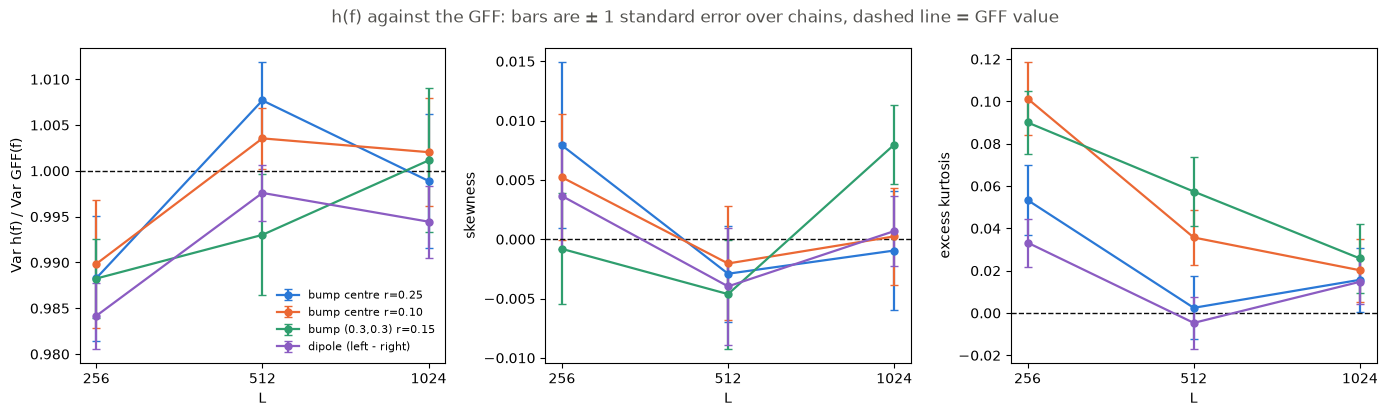

In [4]:
rows = tf.trend(name, funcs)
tf.trend_table(rows, project_to=250_000)   # project_to: total samples per L you are considering; None hides the column
if rows:
    tf.plot_trend(rows)
    plt.show()

## A4. One size in detail
In the figure the orange histogram is the exact law of the GFF pairing, drawn with as many samples as h has (`n_gff=...` changes that; `n_fields=300` adds a check with full lattice GFF fields).

In [5]:
Ls = tf.available_Ls(name)
L_show = max(Ls) if Ls else None          # or choose by hand, e.g. L_show = 512
print("sizes with data:", Ls, "-> showing", L_show)

sizes with data: [256, 512, 1024] -> showing 1024


In [6]:
if L_show:
    res = tf.compare(L_show, name, funcs)

L = 1024: 12 chains, 250008 samples.   Errors: standard error over chains.

bump centre r=0.25
   Var h(f)            = 4.2876e-04 +- 3.1e-06
   Var GFF(f) / pi     = 4.2923e-04 (lattice, mesh 1/1024)    4.2923e-04 (continuum, mesh 1/2048)
   ratio h / GFF       = 0.9989 +- 0.0073 (lattice)    0.9989 (continuum)
   skewness            = -0.001 +- 0.005     excess kurtosis = +0.016 +- 0.015   (GFF: 0, 0)
   autocorrelation time = 0.5 samples for h(f), 2.2 for h(f)^2 (the larger one sets the thinning)
   KS distance to N(0, Var GFF), thinning 5 (50004 values): D = 0.0024, p = 0.93

bump centre r=0.10
   Var h(f)            = 1.8491e-05 +- 1.1e-07
   Var GFF(f) / pi     = 1.8453e-05 (lattice, mesh 1/1024)    1.8453e-05 (continuum, mesh 1/2048)
   ratio h / GFF       = 1.0020 +- 0.0059 (lattice)    1.0020 (continuum)
   skewness            = +0.000 +- 0.004     excess kurtosis = +0.020 +- 0.015   (GFF: 0, 0)
   autocorrelation time = 0.5 samples for h(f), 1.7 for h(f)^2 (the larger one set

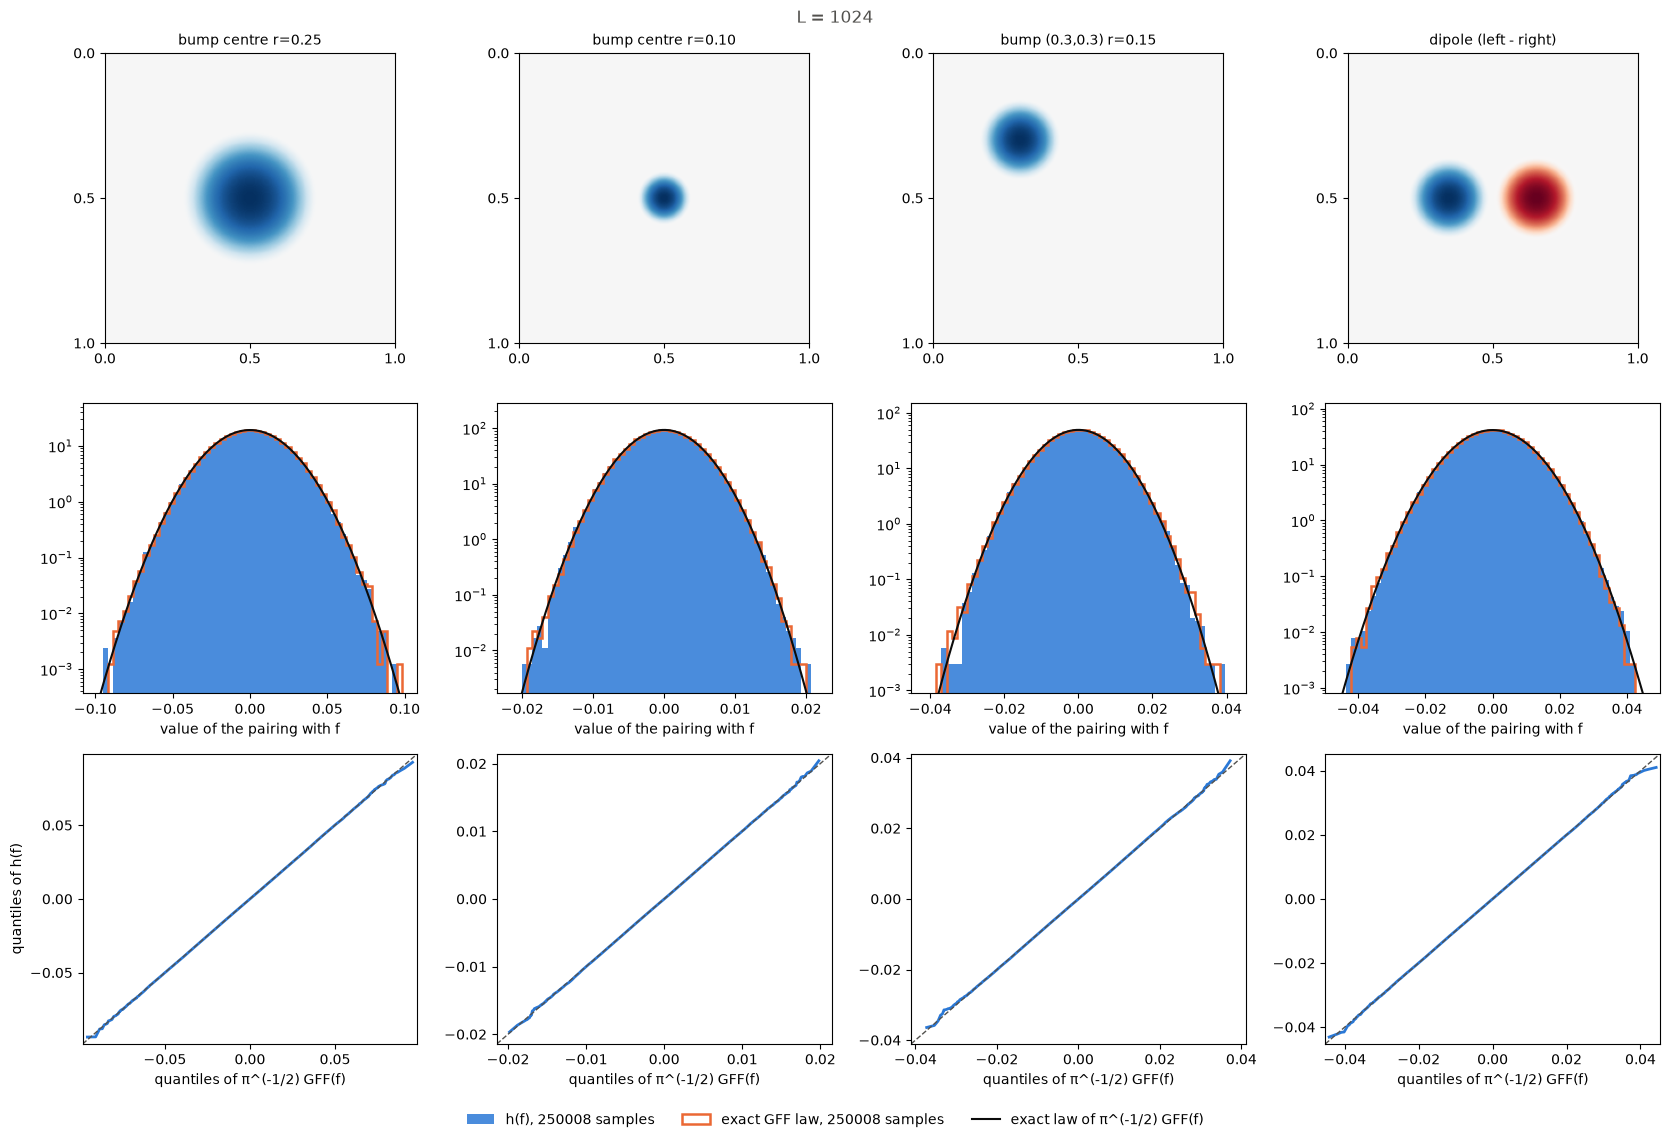

In [7]:
if L_show:
    fig = tf.figure(L_show, name, funcs)
    plt.show()

## A5. Do more samples help? Estimates against number of samples

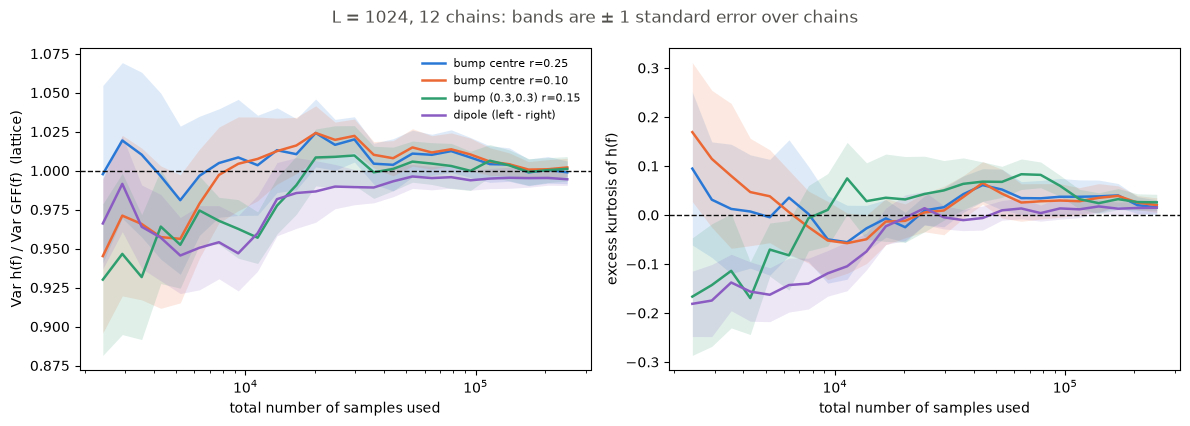

In [8]:
if L_show:
    fig = tf.plot_running(L_show, name, funcs)
    plt.show()

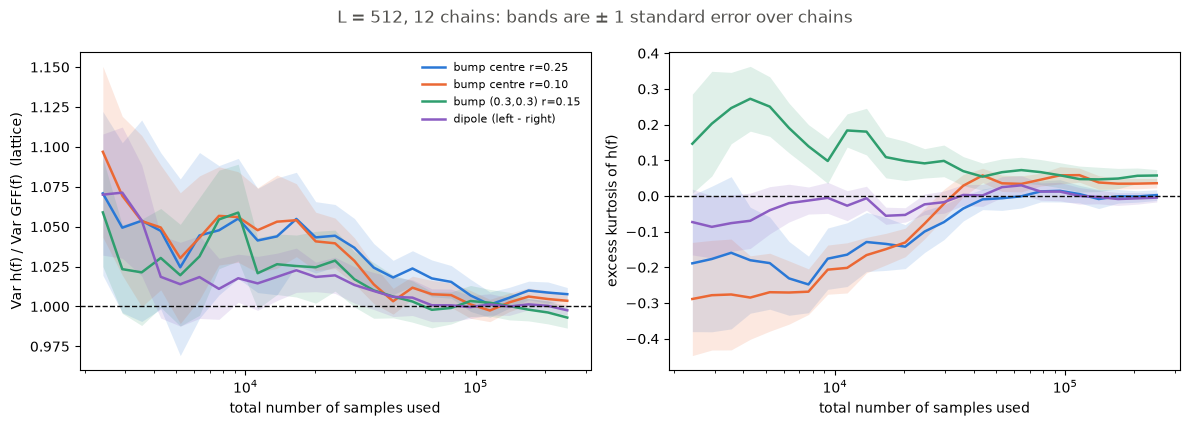

In [9]:
L_show = 512

if L_show:
    fig = tf.plot_running(L_show, name, funcs)
    plt.show()

# Part B. Main run against the GFF

In [10]:
res = d.summarize()

L=   32: 24 chains,  1008000 samples | Var h(centre) = 0.2589 +- 0.0007 (from h^2: 0.2590) | E h = +0.0005 +- 0.0005 | largest cluster = 148.6 +- 0.1 vertices
L=   64: 24 chains,  1008000 samples | Var h(centre) = 0.3015 +- 0.0007 (from h^2: 0.3016) | E h = -0.0005 +- 0.0006 | largest cluster = 490.3 +- 0.6 vertices
L=  128: 24 chains,  1008000 samples | Var h(centre) = 0.3421 +- 0.0007 (from h^2: 0.3423) | E h = +0.0006 +- 0.0007 | largest cluster = 1639.6 +- 2.0 vertices
L=  256: 24 chains,  1008000 samples | Var h(centre) = 0.3773 +- 0.0007 (from h^2: 0.3776) | E h = +0.0005 +- 0.0006 | largest cluster = 5478.6 +- 6.7 vertices
L=  512: 12 chains,  1000008 samples | Var h(centre) = 0.4159 +- 0.0008 (from h^2: 0.4159) | E h = -0.0000 +- 0.0005 | largest cluster = 18336.4 +- 36.2 vertices
L= 1024: 12 chains,   250008 samples | Var h(centre) = 0.4506 +- 0.0017 (from h^2: 0.4515) | E h = -0.0012 +- 0.0009 | largest cluster = 61621.5 +- 176.0 vertices
L 32->64: variance slope per ln L = 0

## B1. Covariance along the centre row against (1/π) G (exact lattice Green function)
Expect agreement from distance 1 on (distance 0 is a lattice-scale difference).

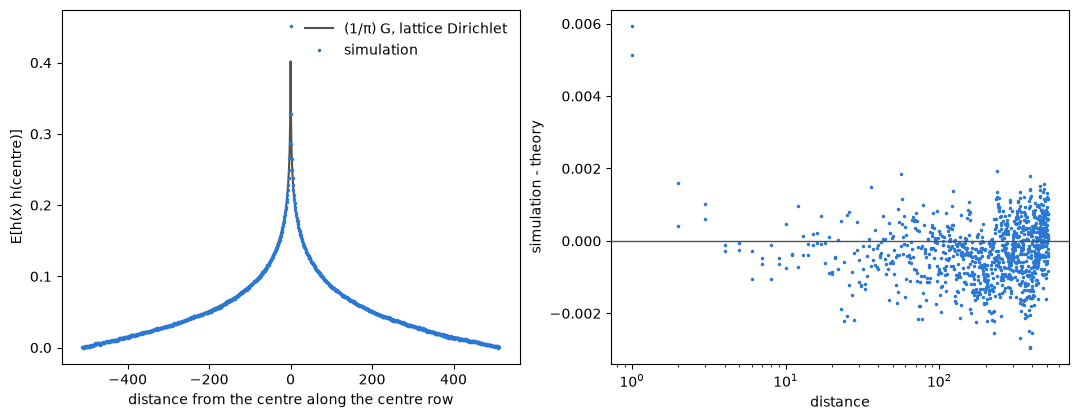

In [11]:
if res:
    gc.cov_figure(res, max(res)); plt.show()

## B2. Variance at the centre: exact lattice GFF subtracted, and fits with finite-size corrections

In [12]:
Ls = np.array(sorted(res)); v = np.array([res[L]["var"] for L in Ls]); e = np.array([res[L]["var_se"] for L in Ls])
x = np.log(Ls); w = 1 / e**2; b_th = 1 / (2 * np.pi**2)

def wls(cols, y):
    A = np.vstack(cols).T
    cov = np.linalg.inv(A.T @ (A * w[:, None])); p = cov @ (A.T @ (w * y))
    return p, np.sqrt(np.diag(cov)), np.sum(w * (y - A @ p)**2), len(y) - A.shape[1]

one = np.ones_like(x)
print("1) exact lattice GFF subtracted: d(L) = Var h(centre) - (1/pi) G_L(centre, centre)")
gff = np.array([gc.green_function(L, L // 2 - 1, L // 2 - 1)[L // 2 - 1, L // 2 - 1] / np.pi for L in Ls])
dd = v - gff
for L, a_, b_, c_ in zip(Ls, gff, dd, e): print(f"   L={L:5d}  GFF {a_:.4f}  d = {b_:.4f} +- {c_:.4f}")
p, s, chi2, dof = wls([one], dd); print(f"   constant fit: d = {p[0]:.4f} +- {s[0]:.4f}, chi2 = {chi2:.1f} / {dof}")
print("2) Var = a + b ln L + c / L^k")
for k in (1, 2):
    p, s, chi2, dof = wls([one, x, Ls**(-float(k))], v)
    print(f"   free b,   k={k}: b = {p[1]:.4f} +- {s[1]:.4f}, c = {p[2]:+.3f}, chi2 = {chi2:.1f} / {dof}")
    p, s, chi2, dof = wls([one, Ls**(-float(k))], v - b_th * x)
    print(f"   b = theory, k={k}: c = {p[1]:+.3f} +- {s[1]:.3f}, chi2 = {chi2:.1f} / {dof}")

1) exact lattice GFF subtracted: d(L) = Var h(centre) - (1/pi) G_L(centre, centre)
   L=   32  GFF 0.2262  d = 0.0327 +- 0.0007
   L=   64  GFF 0.2613  d = 0.0402 +- 0.0007
   L=  128  GFF 0.2964  d = 0.0457 +- 0.0007
   L=  256  GFF 0.3316  d = 0.0458 +- 0.0007
   L=  512  GFF 0.3667  d = 0.0493 +- 0.0008
   L= 1024  GFF 0.4018  d = 0.0488 +- 0.0017
   constant fit: d = 0.0426 +- 0.0003, chi2 = 353.9 / 5
2) Var = a + b ln L + c / L^k
   free b,   k=1: b = 0.0514 +- 0.0008, c = -0.472, chi2 = 7.3 / 3
   b = theory, k=1: c = -0.532 +- 0.029, chi2 = 8.1 / 4
   free b,   k=2: b = 0.0533 +- 0.0005, c = -9.049, chi2 = 8.4 / 3
   b = theory, k=2: c = -14.826 +- 0.826, chi2 = 32.7 / 4


## B3. Variance at every face against the exact lattice GFF
Var h(u) = E[N_odd(u)] was accumulated at every face. The difference should be roughly constant in the bulk.

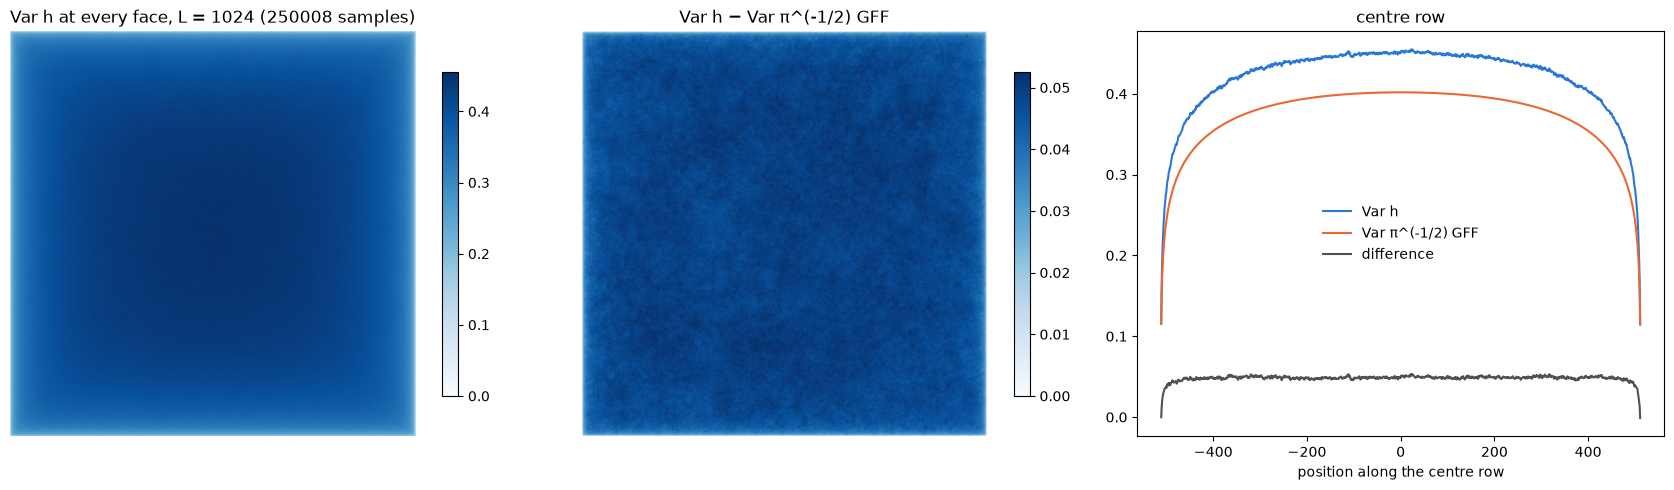

In [13]:
if res:
    gc.variance_map_figure(res, max(res)); plt.show()

## B4. Exact distribution of h(centre)
Given N_odd = k, h(centre) is a sum of k fair signs, so its distribution follows from the saved histogram of N_odd.

In [14]:
for L in sorted(res):
    r = gc.h_centre_distribution(L)
    pm = dict(zip(r["m"], r["pm"]))
    tail = "  ".join(f"P(|h|>={k}) = {sum(p for m, p in pm.items() if abs(m) >= k):.2e}" for k in (1, 2, 3, 4))
    print(f"L={L:5d} ({r['n']} samples): largest N_odd seen = {len(r['pN']) - 1}  |  {tail}")

L=   32 (1008000 samples): largest N_odd seen = 2  |  P(|h|>=1) = 2.57e-01  P(|h|>=2) = 6.08e-04  P(|h|>=3) = 0.00e+00  P(|h|>=4) = 0.00e+00
L=   64 (1008000 samples): largest N_odd seen = 3  |  P(|h|>=1) = 2.97e-01  P(|h|>=2) = 1.65e-03  P(|h|>=3) = 2.48e-07  P(|h|>=4) = 0.00e+00
L=  128 (1008000 samples): largest N_odd seen = 3  |  P(|h|>=1) = 3.32e-01  P(|h|>=2) = 3.44e-03  P(|h|>=3) = 7.44e-07  P(|h|>=4) = 0.00e+00
L=  256 (1008000 samples): largest N_odd seen = 3  |  P(|h|>=1) = 3.59e-01  P(|h|>=2) = 5.94e-03  P(|h|>=3) = 2.73e-06  P(|h|>=4) = 0.00e+00
L=  512 (1000008 samples): largest N_odd seen = 3  |  P(|h|>=1) = 3.87e-01  P(|h|>=2) = 9.49e-03  P(|h|>=3) = 1.50e-05  P(|h|>=4) = 0.00e+00
L= 1024 (250008 samples): largest N_odd seen = 3  |  P(|h|>=1) = 4.10e-01  P(|h|>=2) = 1.33e-02  P(|h|>=3) = 3.30e-05  P(|h|>=4) = 0.00e+00


## B5. Pictures: one sample of h next to one independent sample of π^(-1/2) GFF
The comparison is in law: no matching blobs, only matching statistics. Another `seed` gives another GFF sample.

std of the displayed fields:  h 0.415   GFF 0.415


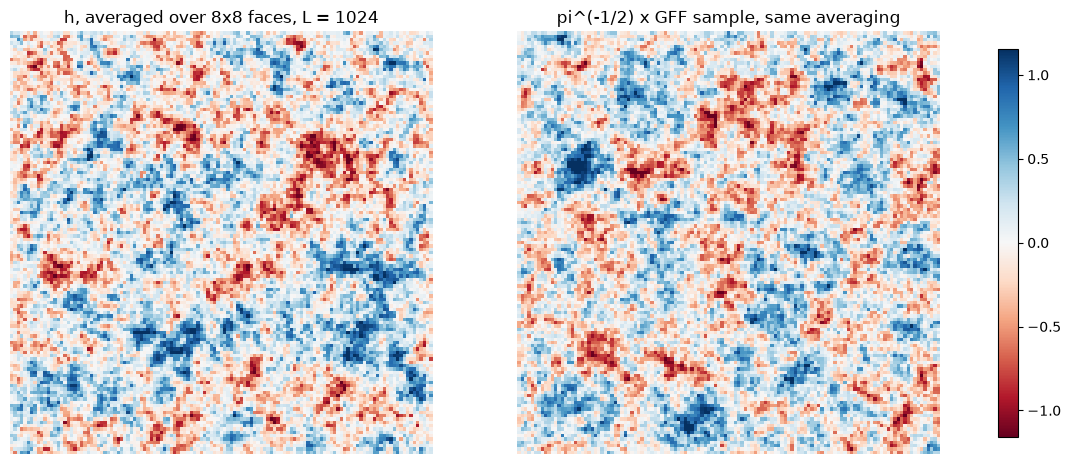

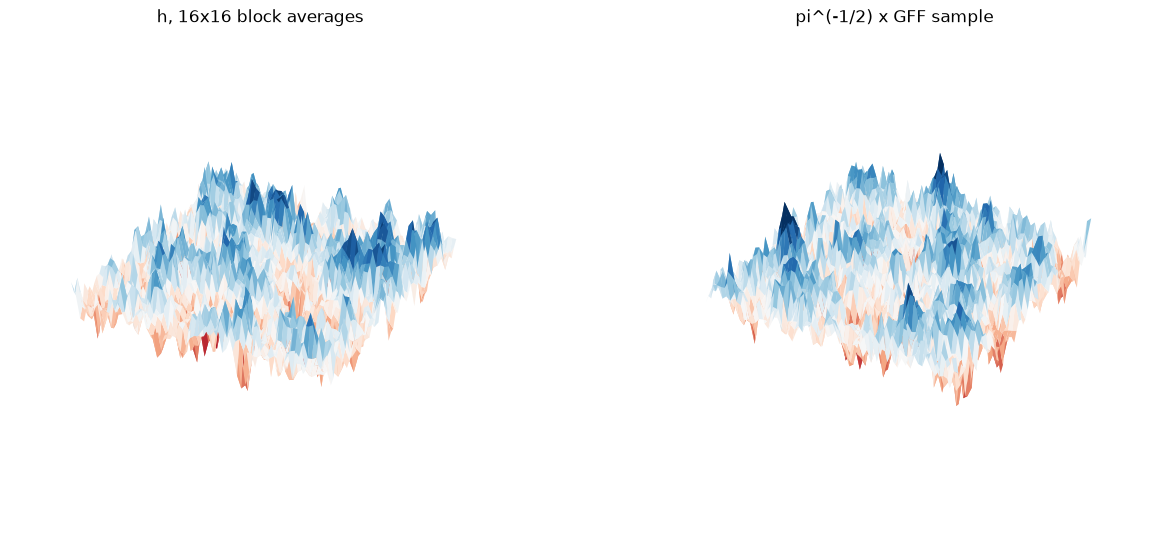

In [15]:
L_show = 1024
path = os.path.join(d.OUT_DIR, f"L{L_show}_snapshot0.npz")
if os.path.exists(path):
    L, omega1, omega2, h, n_odd = d.load_snapshot(path)
    gc.compare_figure(h, L, block=max(2, L // 128), seed=0); plt.show()
    gc.surface_figure(h, L, block=max(4, L // 64), seed=0); plt.show()
else:
    print("no snapshot for this size")

## B6. Many samples of h against many GFF samples (optional)
This cell **draws new samples in the notebook** (L = 512 with 1000 samples: 2-3 minutes; nothing is saved, the saved runs are not touched). Remove the `# ` to use it.

L = 512, 1000 samples of h and of pi^(-1/2) GFF
  centre:  Var h 0.3839   Var GFF 0.3500
  h(centre) values: -2: 2, -1: 179, 0: 631, 1: 185, 2: 3
  max |h| over the lattice: 2: 711, 3: 289   (mean 2.29)   max |GFF|: mean 2.63, range 2.20-3.38
  block averages (32x32, interior): std h 0.3685  GFF 0.3792 | excess kurtosis h +0.091  GFF +0.012


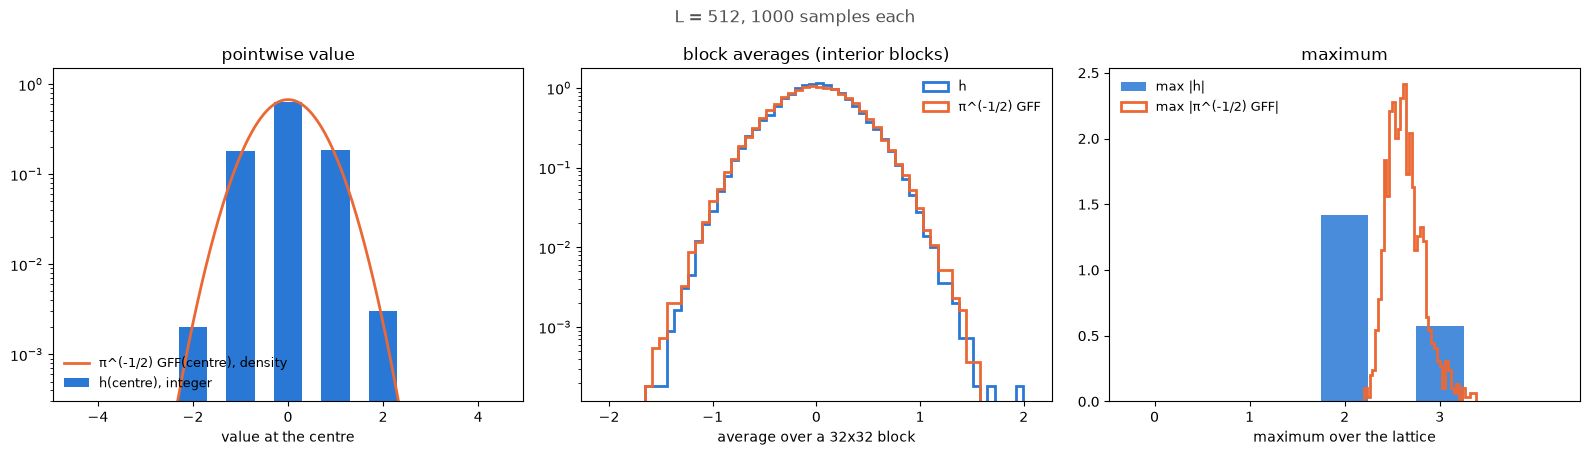

In [16]:
e = gc.h_ensemble(512, 1000, seed=1)
gc.ensemble_summary(e)
gc.ensemble_figure(e); plt.show()

# Part C. Figures for the presentation

All of them are drawn at slide size and saved in `Graficos/` (the functions live in `custom_packages/presentation_figures.py`). Each function has a `titulo` argument: `titulo=None` removes the title.

figures are saved in: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos
guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Funciones_test_1.png


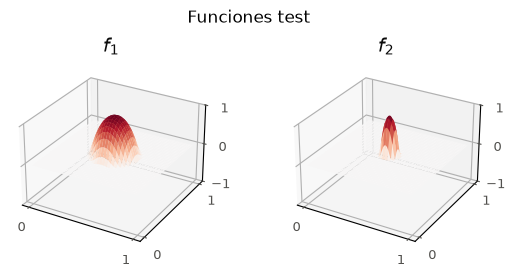

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Funciones_test_2.png


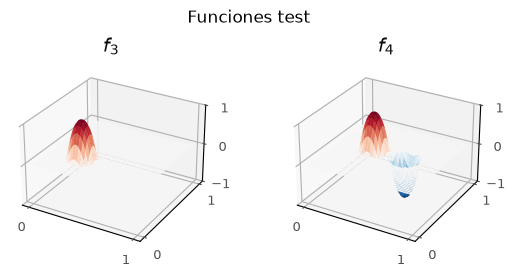

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Comparacion_Funciones_test_1.png


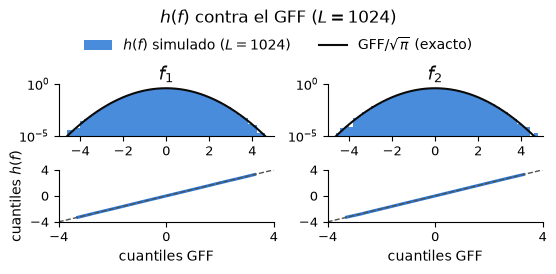

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Comparacion_Funciones_test_2.png


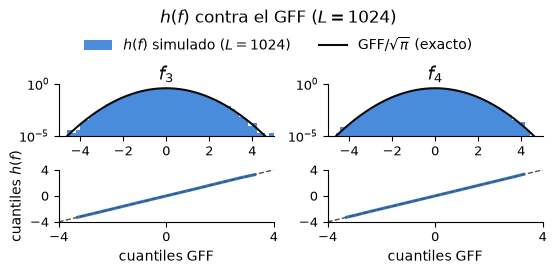

In [17]:
print("figures are saved in:", pf.GRAFICOS)

# test functions (two per figure) and h(f) against the GFF
pf.figura_funciones_test([0, 1], "Funciones_test_1.png")
pf.figura_funciones_test([2, 3], "Funciones_test_2.png")
pf.figura_comparacion(1024, [0, 1], "Comparacion_Funciones_test_1.png", name, funcs)
pf.figura_comparacion(1024, [2, 3], "Comparacion_Funciones_test_2.png", name, funcs)

L=   32: 24 chains,  1008000 samples | Var h(centre) = 0.2589 +- 0.0007 (from h^2: 0.2590) | E h = +0.0005 +- 0.0005 | largest cluster = 148.6 +- 0.1 vertices
L=   64: 24 chains,  1008000 samples | Var h(centre) = 0.3015 +- 0.0007 (from h^2: 0.3016) | E h = -0.0005 +- 0.0006 | largest cluster = 490.3 +- 0.6 vertices
L=  128: 24 chains,  1008000 samples | Var h(centre) = 0.3421 +- 0.0007 (from h^2: 0.3423) | E h = +0.0006 +- 0.0007 | largest cluster = 1639.6 +- 2.0 vertices
L=  256: 24 chains,  1008000 samples | Var h(centre) = 0.3773 +- 0.0007 (from h^2: 0.3776) | E h = +0.0005 +- 0.0006 | largest cluster = 5478.6 +- 6.7 vertices
L=  512: 12 chains,  1000008 samples | Var h(centre) = 0.4159 +- 0.0008 (from h^2: 0.4159) | E h = -0.0000 +- 0.0005 | largest cluster = 18336.4 +- 36.2 vertices
L= 1024: 12 chains,   250008 samples | Var h(centre) = 0.4506 +- 0.0017 (from h^2: 0.4515) | E h = -0.0012 +- 0.0009 | largest cluster = 61621.5 +- 176.0 vertices
L 32->64: variance slope per ln L = 0

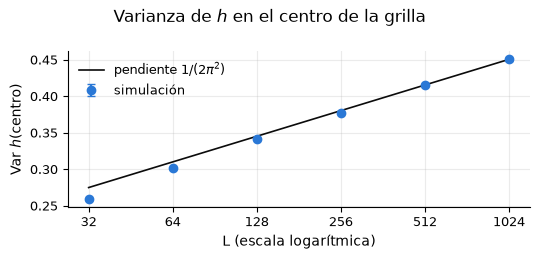

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Convergencia_al_GFF_1024.png


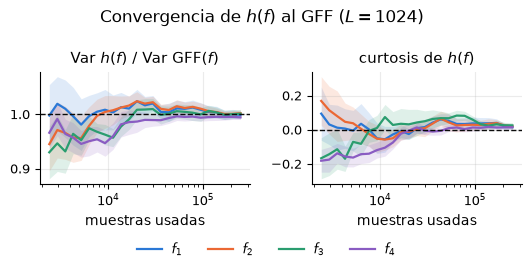

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\No_gaussianidad_h.png


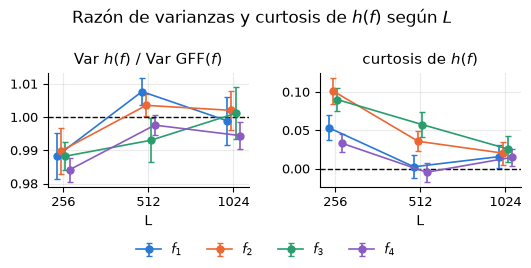

In [18]:
# variance at the centre (main run), convergence with the number of samples, trend with L
res_main = d.summarize()
pf.figura_varianza(res_main, "Varianza_h_y_GFF.png")
pf.figura_convergencia(1024, "Convergencia_al_GFF_1024.png", name, funcs)
pf.figura_gaussianidad("No_gaussianidad_h.png", name, funcs)